# Lab 2: Classification Using KNN and RNN Algorithms

**Name:** Aditya Rayarapu
**Course:** MSCS-634 - Advanced Big Data and Data Mining
**Assignment:** Lab 2: Classification Using KNN and RNN Algorithms

## Objective

The objective of this lab is to explore and compare the performance
of K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) classifiers
using the Wine dataset from scikit-learn.

The experiment evaluates different K values and radius values,
visualizes classification accuracy, and discusses how parameter
selection influences predictive performance.

# 1. Imports and reproducible setup

The notebook uses pandas and NumPy for inspection, Matplotlib for visualizations, and scikit-learn for data loading, training, and evaluation. All data comes bundled with scikit-learn, so **no external CSV download is needed**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier

RANDOM_STATE = 42
OUTPUT_DIR = Path("screenshots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)
print("Environment ready")
print("scikit-learn version:", sklearn.__version__)
print("Figures will be saved to:", OUTPUT_DIR.resolve())

Environment ready
scikit-learn version: 1.9.1
Figures will be saved to: /Users/adityarayarapu/Downloads/MSCS-634-Lab-2/screenshots


# 2. Load and prepare the Wine dataset — Data Preparation and Cleaning

The Wine dataset contains **178 observations**, **13 continuous numerical predictors**, and **3 target classes** representing different wine cultivars. We inspect features, class labels, descriptive statistics, missing data, and duplicate rows before modeling.

In [2]:
# Load the dataset as a pandas DataFrame/Series.
wine = load_wine(as_frame=True)
X = wine.data.copy()
y = wine.target.copy()

df = X.copy()
df["target"] = y

print("Samples:", X.shape[0])
print("Predictor features:", X.shape[1])
print("Number of classes:", y.nunique())
print("Target names:", list(wine.target_names))
print("Feature names:", X.columns.tolist())
print("\nFirst five rows:")
display(df.head())

Samples: 178
Predictor features: 13
Number of classes: 3
Target names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [12]:
print("Feature data types:")
display(X.dtypes.rename("dtype").to_frame())

print("Summary statistics for numerical features:")
display(X.describe().T.round(2))

missing = df.isna().sum()
duplicates = int(df.duplicated().sum())
print("Total missing values:", int(missing.sum()))
print("Duplicate rows:", duplicates)
display(missing.rename("missing_count").to_frame())

if int(missing.sum()) == 0 and duplicates == 0:
    print("Data-quality conclusion: No imputation or duplicate removal is necessary.")
else:
    print("Review missing or duplicate records before modeling.")

Feature data types:


,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


Summary statistics for numerical features:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


Total missing values: 0
Duplicate rows: 0


,missing_count
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Data-quality conclusion: No imputation or duplicate removal is necessary.


Class distribution:


,class_id,class_name,count,percent
0,0,class_0,59,33.15
1,1,class_1,71,39.89
2,2,class_2,48,26.97


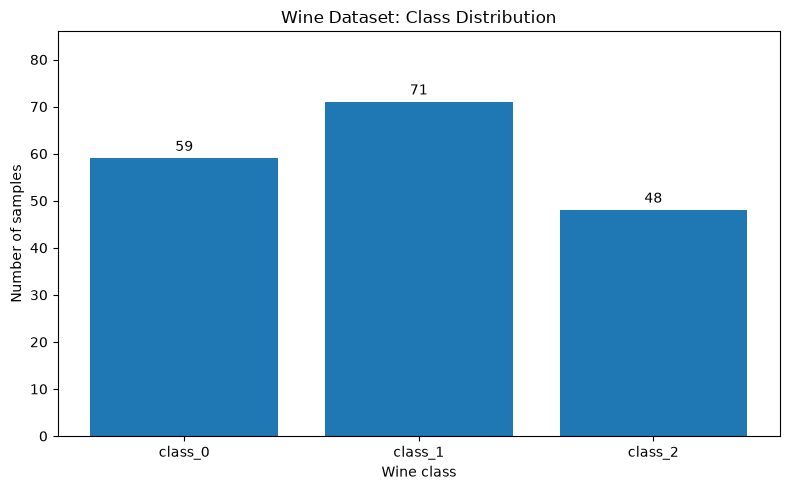

In [3]:
# Class frequencies and proportions; use a fixed class order.
class_counts = y.value_counts().sort_index()
class_distribution = pd.DataFrame({
    "class_id": class_counts.index,
    "class_name": [wine.target_names[i] for i in class_counts.index],
    "count": class_counts.values,
    "percent": (100 * class_counts.values / len(y)).round(2),
})
print("Class distribution:")
display(class_distribution)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(class_distribution["class_name"], class_distribution["count"])
ax.bar_label(bars, padding=3)
ax.set(title="Wine Dataset: Class Distribution", xlabel="Wine class", ylabel="Number of samples")
ax.set_ylim(0, max(class_distribution["count"]) + 15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "wine_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Split into 80% training and 20% testing

To compare KNN and RNN fairly, both use the **same** test examples. Stratification maintains class proportions, and a fixed random seed makes results repeatable.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training rows:", len(X_train), "(80% approximately)")
print("Testing rows:", len(X_test), "(20% approximately)")
print("\nTraining class counts:")
display(y_train.value_counts().sort_index().rename("count").to_frame())
print("Testing class counts:")
display(y_test.value_counts().sort_index().rename("count").to_frame())

assert X_train.shape == (142, 13)
assert X_test.shape == (36, 13)

Training rows: 142 (80% approximately)
Testing rows: 36 (20% approximately)

Training class counts:


,count
target,
0,47
1,57
2,38


Testing class counts:


,count
target,
0,12
1,14
2,10


# 4. KNN Model Development

KNN classifies a new sample by voting among its **fixed number** of nearest training observations. We evaluate every assignment-specified `k`, using `weights='uniform'` and Euclidean distance. **Accuracy** is the fraction of correctly predicted test labels.

In [5]:
k_values = [1, 5, 11, 15, 21]
knn_models = {}
knn_results = []

for k in k_values:
    model = KNeighborsClassifier(
        n_neighbors=k,
        weights="uniform",
        metric="euclidean",
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    knn_models[k] = model
    knn_results.append({"k": k, "accuracy": accuracy, "accuracy_percent": 100 * accuracy})

knn_results_df = pd.DataFrame(knn_results)
print("KNN test-set accuracy for every k:")
display(knn_results_df.round({"accuracy": 4, "accuracy_percent": 2}))

KNN test-set accuracy for every k:


,k,accuracy,accuracy_percent
0,1,0.7778,77.78
1,5,0.8056,80.56
2,11,0.8056,80.56
3,15,0.8056,80.56
4,21,0.8056,80.56


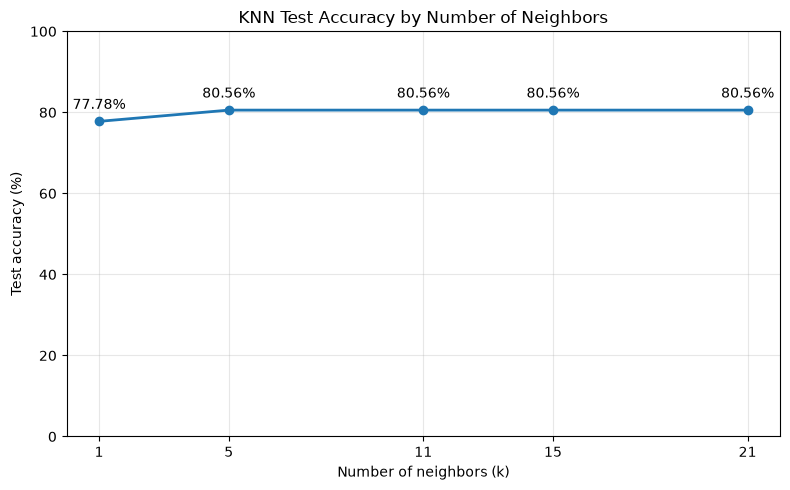

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(knn_results_df["k"], knn_results_df["accuracy_percent"], marker="o", linewidth=2)
ax.set(title="KNN Test Accuracy by Number of Neighbors", xlabel="Number of neighbors (k)", ylabel="Test accuracy (%)")
ax.set_xticks(k_values)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
for k, acc in zip(knn_results_df["k"], knn_results_df["accuracy_percent"]):
    ax.annotate(f"{acc:.2f}%", (k, acc), xytext=(0, 9), textcoords="offset points", ha="center")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "knn_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. RNN Model Development

Radius Neighbors selects **all** training observations within a fixed distance from each test example. Therefore, the number of neighbors can vary across samples and may even be zero.

To handle zero-neighbor samples safely, `outlier_label='most_frequent'` predicts the most common training class for those cases. We also count zero-neighbor test cases for transparency; this avoids silently treating the fallback as an ordinary neighbor-based prediction.

In [7]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_models = {}
rnn_results = []

for radius in radius_values:
    model = RadiusNeighborsClassifier(
        radius=radius,
        weights="uniform",
        metric="euclidean",
        outlier_label="most_frequent",
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    neighbor_indices = model.radius_neighbors(X_test, return_distance=False)
    neighbor_counts = np.array([len(indices) for indices in neighbor_indices])

    rnn_models[radius] = model
    rnn_results.append({
        "radius": radius,
        "accuracy": accuracy,
        "accuracy_percent": 100 * accuracy,
        "no_neighbor_test_samples": int(np.sum(neighbor_counts == 0)),
        "mean_neighbors": float(np.mean(neighbor_counts)),
    })

rnn_results_df = pd.DataFrame(rnn_results)
print("Radius Neighbors test accuracy and neighborhood statistics:")
display(rnn_results_df.round({"accuracy": 4, "accuracy_percent": 2, "mean_neighbors": 2}))

Radius Neighbors test accuracy and neighborhood statistics:


,radius,accuracy,accuracy_percent,no_neighbor_test_samples,mean_neighbors
0,350,0.7222,72.22,0,80.53
1,400,0.6944,69.44,0,87.86
2,450,0.6944,69.44,0,94.83
3,500,0.6944,69.44,0,100.06
4,550,0.6667,66.67,0,105.97
5,600,0.6667,66.67,0,110.97


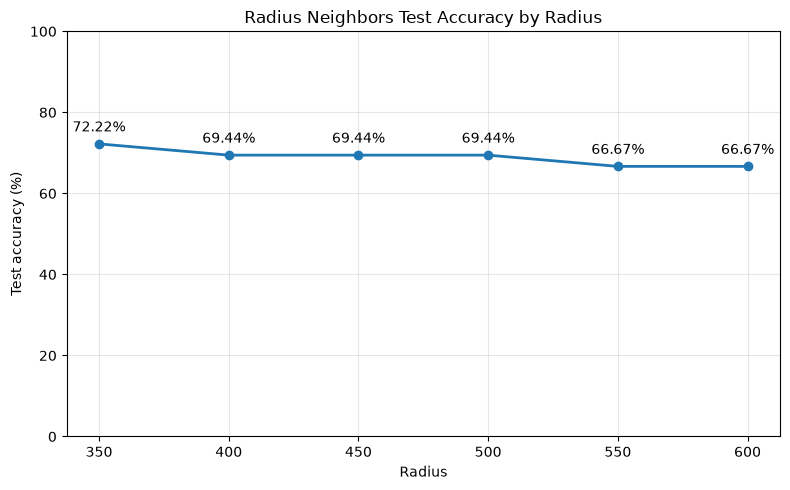

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rnn_results_df["radius"], rnn_results_df["accuracy_percent"], marker="o", linewidth=2)
ax.set(title="Radius Neighbors Test Accuracy by Radius", xlabel="Radius", ylabel="Test accuracy (%)")
ax.set_xticks(radius_values)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
for radius, acc in zip(rnn_results_df["radius"], rnn_results_df["accuracy_percent"]):
    ax.annotate(f"{acc:.2f}%", (radius, acc), xytext=(0, 9), textcoords="offset points", ha="center")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rnn_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Model Comparison and Insights

For the **descriptive comparison required by this lab**, select the highest observed test accuracy for each algorithm; if configurations tie, `idxmax()` chooses the first of the tied values (the smaller `k` or radius in these ordered grids).

**Methodological note:** These choices are selected using the test set because the assignment requests a single 80/20 split and comparison of the supplied parameter values. A stricter predictive evaluation would choose parameters on a separate validation fold or by cross-validation, then evaluate once on an untouched test set.

In [8]:
best_knn_row = knn_results_df.loc[knn_results_df["accuracy"].idxmax()]
best_rnn_row = rnn_results_df.loc[rnn_results_df["accuracy"].idxmax()]
best_k = int(best_knn_row["k"])
best_radius = int(best_rnn_row["radius"])

comparison_df = pd.DataFrame({
    "model": [f"KNN (k={best_k})", f"Radius Neighbors (radius={best_radius})"],
    "accuracy_percent": [best_knn_row["accuracy_percent"], best_rnn_row["accuracy_percent"]],
})
comparison_df["accuracy_percent"] = comparison_df["accuracy_percent"].round(2)

print(f"Best KNN setting: k={best_k}, test accuracy={best_knn_row['accuracy_percent']:.2f}%")
print(f"Best RNN setting: radius={best_radius}, test accuracy={best_rnn_row['accuracy_percent']:.2f}%")
print(f"Accuracy difference: {best_knn_row['accuracy_percent'] - best_rnn_row['accuracy_percent']:.2f} percentage points")
display(comparison_df)

Best KNN setting: k=5, test accuracy=80.56%
Best RNN setting: radius=350, test accuracy=72.22%
Accuracy difference: 8.33 percentage points


,model,accuracy_percent
0,KNN (k=5),80.56
1,Radius Neighbors (radius=350),72.22


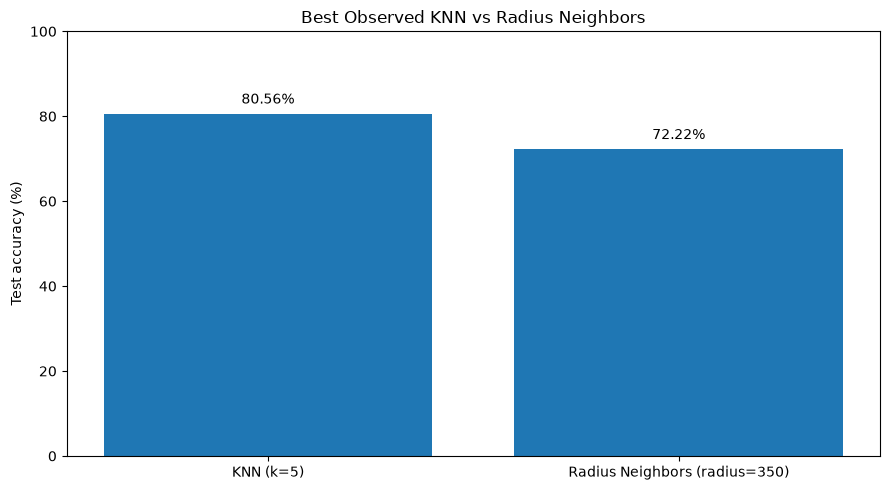

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(comparison_df["model"], comparison_df["accuracy_percent"])
ax.bar_label(bars, fmt="%.2f%%", padding=5)
ax.set(title="Best Observed KNN vs Radius Neighbors", ylabel="Test accuracy (%)")
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Additional model diagnostics: per-class performance and confusion matrices

Overall accuracy can hide mistakes in less common classes. Precision, recall, F1-score, and confusion matrices reveal where each classifier makes errors. Diagonal confusion-matrix cells are correct predictions; off-diagonal cells are mistakes.

In [10]:
knn_predictions = knn_models[best_k].predict(X_test)
rnn_predictions = rnn_models[best_radius].predict(X_test)

print(f"KNN classification report (k={best_k}):")
print(classification_report(y_test, knn_predictions, target_names=wine.target_names, zero_division=0))
print(f"Radius Neighbors classification report (radius={best_radius}):")
print(classification_report(y_test, rnn_predictions, target_names=wine.target_names, zero_division=0))

KNN classification report (k=5):
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.77      0.71      0.74        14
     class_2       0.64      0.70      0.67        10

    accuracy                           0.81        36
   macro avg       0.80      0.80      0.80        36
weighted avg       0.81      0.81      0.81        36

Radius Neighbors classification report (radius=350):
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.58      1.00      0.74        14
     class_2       1.00      0.10      0.18        10

    accuracy                           0.72        36
   macro avg       0.86      0.67      0.63        36
weighted avg       0.84      0.72      0.66        36



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, knn_predictions, display_labels=wine.target_names,
    cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title(f"KNN Confusion Matrix (k={best_k})")
ConfusionMatrixDisplay.from_predictions(
    y_test, rnn_predictions, display_labels=wine.target_names,
    cmap="Oranges", ax=axes[1], colorbar=False,
)
axes[1].set_title(f"Radius Neighbors Confusion Matrix (r={best_radius})")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()